# Análisis exploratorio y resultado de combinar las bases de datos 

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (11, 5)

raw_path = Path("../data/processed")

archivos = list(raw_path.glob("*.csv"))

len(archivos), archivos


(3,
 [WindowsPath('../data/processed/numero_estudiantes_intercambio_recibidos.csv'),
  WindowsPath('../data/processed/porcentaje_alumnos_hicieron_intercambio.csv'),
  WindowsPath('../data/processed/promedio_contribuciones_cien_tesis.csv')])

In [4]:

df_entrada = pd.read_csv(
    raw_path / "numero_estudiantes_intercambio_recibidos.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
    dtype={"COD_RUCT": str}
)

df_salida = pd.read_csv(
    raw_path / "porcentaje_alumnos_hicieron_intercambio.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
    dtype={"COD_RUCT": str}
)

df_investigacion = pd.read_csv(
    raw_path / "promedio_contribuciones_cien_tesis.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
    dtype={"COD_RUCT": str}
)

for nombre, df in {
    "Movilidad entrante": df_entrada,
    "Movilidad saliente": df_salida,
    "Investigación": df_investigacion
}.items():
    print(f"\n{nombre}")
    print("Dimensiones:", df.shape)
    print("Columnas:", df.columns.tolist())
    print(df.dtypes)
    display(df.head())



Movilidad entrante
Dimensiones: (159, 9)
Columnas: ['COD_RUCT', 'TITULACION', 'CENTRO', '2019-20', '2020-21', '2021-22', '2022-23', '2023-24', '2024-25']
COD_RUCT       object
TITULACION     object
CENTRO         object
2019-20       float64
2020-21       float64
2021-22       float64
2022-23       float64
2023-24       float64
2024-25       float64
dtype: object


,COD_RUCT,TITULACION,CENTRO,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25
0,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,51.0,10.0,21.0,18.0,14.0,23.0
1,2500801,GRADO EN CIENCIAS AMBIENTALES,ESCUELA POLITECNICA SUPERIOR DE GANDIA,25.0,6.0,20.0,19.0,14.0,16.0
2,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,31.0,14.0,17.0,32.0,24.0,NaN
3,2501355,GRADO EN TURISMO,ESCUELA POLITECNICA SUPERIOR DE GANDIA,44.0,17.0,47.0,37.0,30.0,32.0
4,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E. POLITÉCNICA SUPERIOR DE ALCOY,14.0,2.0,3.0,6.0,3.0,11.0



Movilidad saliente
Dimensiones: (141, 8)
Columnas: ['COD_RUCT', 'TITULACION', 'CENTRO', '2020-21', '2021-22', '2022-23', '2023-24', '2024-25']
COD_RUCT       object
TITULACION     object
CENTRO         object
2020-21        object
2021-22       float64
2022-23       float64
2023-24       float64
2024-25       float64
dtype: object


,COD_RUCT,TITULACION,CENTRO,2020-21,2021-22,2022-23,2023-24,2024-25
0,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2.08,8.33,10.17,8.51,16.67
1,2500801,GRADO EN CIENCIAS AMBIENTALES,ESCUELA POLITECNICA SUPERIOR DE GANDIA,11.11,26.67,31.82,30.00,25.64
2,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,21.05,50.00,28.17,23.53,NaN
3,2501355,GRADO EN TURISMO,ESCUELA POLITECNICA SUPERIOR DE GANDIA,16.33,31.71,11.11,19.05,16.67
4,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E. POLITÉCNICA SUPERIOR DE ALCOY,14.93,13.04,27.14,26.32,25.00



Investigación
Dimensiones: (32, 7)
Columnas: ['COD_RUCT', 'TITULACION', '2020-21', '2021-22', '2022-23', '2023-24', '2024-25']
COD_RUCT       object
TITULACION     object
2020-21       float64
2021-22       float64
2022-23       float64
2023-24       float64
2024-25       float64
dtype: object


,COD_RUCT,TITULACION,2020-21,2021-22,2022-23,2023-24,2024-25
0,5600035,PROGRAMA DE DOCTORADO EN SISTEMAS PROPULSIVOS ...,6.22,6.00,5.32,5.00,5.53
1,5600036,PROGRAMA DE DOCTORADO EN CIENCIA Y TECNOLOGÍA ...,6.13,6.83,10.00,9.15,10.17
2,5600037,PROGRAMA DE DOCTORADO EN INFORMÁTICA,9.56,8.28,7.63,8.67,6.92
3,5600038,"PROGRAMA DE DOCTORADO EN ARQUITECTURA, EDIFICA...",11.88,8.50,8.67,7.86,8.37
4,5600039,PROGRAMA DE DOCTORADO EN ECONOMÍA AGROALIMENTARIA,4.00,3.50,5.00,8.57,8.17


# Datos ausentes y duplicados

Vemos que a lo largo de los años tenemos valores ausentes, pueden tratarse de grados nuevos que se han ido incorporando a la universidad.

In [6]:
for nombre, df in {
    "Entrada": df_entrada,
    "Salida": df_salida,
    "Investigación": df_investigacion
}.items():
    print(f"\n--- {nombre} ---")
    print("Filas duplicadas:", df.duplicated().sum())
    print("Valores ausentes:")
    display(df.isna().sum().to_frame("Nulos"))

    # Filas con al menos un nulo
    filas_nulas = df[df.isna().any(axis=1)]
    print(f"Filas con algún nulo: {len(filas_nulas)}")
    display(filas_nulas)


--- Entrada ---
Filas duplicadas: 0
Valores ausentes:


,Nulos
COD_RUCT,0
TITULACION,0
CENTRO,0
2019-20,46
2020-21,46
2021-22,40
2022-23,33
2023-24,30
2024-25,28


Filas con algún nulo: 73


,COD_RUCT,TITULACION,CENTRO,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25
2,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,31.0,14.0,17.0,32.0,24.0,NaN
5,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO IND...,NaN,NaN,NaN,NaN,78.0,58.0
6,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E.T.S. DE INGENIERIA DEL DISEÑO,76.0,33.0,88.0,86.0,NaN,NaN
14,2501653,GRADO EN INGENIERÍA AEROESPACIAL,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO IND...,NaN,NaN,NaN,NaN,41.0,61.0
15,2501653,GRADO EN INGENIERÍA AEROESPACIAL,E.T.S. DE INGENIERIA DEL DISEÑO,37.0,12.0,39.0,52.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...
154,4318256,MÁSTER UNIVERSITARIO EN SEGURIDAD INDUSTRIAL,E.T.S.I. INDUSTRIALES,NaN,NaN,NaN,NaN,0.0,0.0
155,4318298,MÁSTER UNIVERSITARIO EN INGENIERÍA EN MOVILIDA...,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO IND...,NaN,NaN,NaN,NaN,0.0,3.0
156,4318372,MÁSTER UNIVERSITARIO EN HUMANIDADES DIGITALES,E.T.S. DE INGENIERÍA INFORMÁTICA,NaN,NaN,NaN,NaN,0.0,0.0
157,4318375,MÁSTER UNIVERSITARIO EN INGENIERÍA ESTRUCTURAL...,"E.T.S.I. CAMINOS, CANALES Y PUERTOS",NaN,NaN,NaN,NaN,0.0,0.0



--- Salida ---
Filas duplicadas: 0
Valores ausentes:


,Nulos
COD_RUCT,0
TITULACION,0
CENTRO,0
2020-21,34
2021-22,29
2022-23,26
2023-24,24
2024-25,21


... (2 outputs left out)


--- Investigación ---
Filas duplicadas: 0
Valores ausentes:


,Nulos
COD_RUCT,0
TITULACION,0
2020-21,2
2021-22,3
2022-23,2
2023-24,1
2024-25,2


Filas con algún nulo: 3


,COD_RUCT,TITULACION,2020-21,2021-22,2022-23,2023-24,2024-25
23,5600356,PROGRAMA DE DOCTORADO EN TÉCNICAS EXPERIMENTAL...,4.0,NaN,6.5,10.5,NaN
30,5601427,"PROGRAMA DE DOCTORADO EN ARQUITECTURA, EDIFICA...",NaN,NaN,NaN,5.0,6.29
31,5601473,PROGRAMA DE DOCTORADO EN CIENCIA Y TECNOLOGÍA ...,NaN,NaN,NaN,NaN,NaN


In [7]:

def transformar_formato_largo(df, nombre_variable):
    df = df.copy()

    columnas_id = [
        col for col in ["COD_RUCT", "TITULACION", "CENTRO"]
        if col in df.columns
    ]

    columnas_curso = [
        col for col in df.columns
        if col not in columnas_id
    ]

    df_largo = df.melt(
        id_vars=columnas_id,
        value_vars=columnas_curso,
        var_name="CURSO",
        value_name=nombre_variable
    )

    # Conversión numérica, admitiendo coma decimal
    df_largo[nombre_variable] = pd.to_numeric(
        df_largo[nombre_variable]
          .astype("string")
          .str.replace(",", ".", regex=False),
        errors="coerce"
    )

    df_largo["COD_RUCT"] = (
        df_largo["COD_RUCT"].astype("string").str.strip()
    )

    if "CENTRO" in df_largo.columns:
        df_largo["CENTRO"] = (
            df_largo["CENTRO"].astype("string").str.strip()
        )

    df_largo["CURSO"] = df_largo["CURSO"].astype(str).str.strip()

    return df_largo


entrada = transformar_formato_largo(
    df_entrada, "MOVILIDAD_ENTRANTE"
)

salida = transformar_formato_largo(
    df_salida, "PORC_MOVILIDAD_SALIENTE"
)

investigacion = transformar_formato_largo(
    df_investigacion, "CONTRIBUCIONES_TESIS"
)

display(entrada.head())
display(salida.head())
display(investigacion.head())


,COD_RUCT,TITULACION,CENTRO,CURSO,MOVILIDAD_ENTRANTE
0,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2019-20,51.0
1,2500801,GRADO EN CIENCIAS AMBIENTALES,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2019-20,25.0
2,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2019-20,31.0
3,2501355,GRADO EN TURISMO,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2019-20,44.0
4,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E. POLITÉCNICA SUPERIOR DE ALCOY,2019-20,14.0


,COD_RUCT,TITULACION,CENTRO,CURSO,PORC_MOVILIDAD_SALIENTE
0,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2020-21,2.08
1,2500801,GRADO EN CIENCIAS AMBIENTALES,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,11.11
2,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,21.05
3,2501355,GRADO EN TURISMO,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,16.33
4,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E. POLITÉCNICA SUPERIOR DE ALCOY,2020-21,14.93


,COD_RUCT,TITULACION,CURSO,CONTRIBUCIONES_TESIS
0,5600035,PROGRAMA DE DOCTORADO EN SISTEMAS PROPULSIVOS ...,2020-21,6.22
1,5600036,PROGRAMA DE DOCTORADO EN CIENCIA Y TECNOLOGÍA ...,2020-21,6.13
2,5600037,PROGRAMA DE DOCTORADO EN INFORMÁTICA,2020-21,9.56
3,5600038,"PROGRAMA DE DOCTORADO EN ARQUITECTURA, EDIFICA...",2020-21,11.88
4,5600039,PROGRAMA DE DOCTORADO EN ECONOMÍA AGROALIMENTARIA,2020-21,4.0


In [13]:
print(entrada.columns.tolist())

['COD_RUCT', 'TITULACION', 'CENTRO', 'CURSO', 'MOVILIDAD_ENTRANTE']


In [18]:

claves = ["COD_RUCT","TITULACION", "CENTRO", "CURSO"]

for nombre, df in {
    "Entrada": entrada,
    "Salida": salida
}.items():

    duplicados = df[
        df.duplicated(subset=claves, keep=False)
    ]

    print(f"{nombre}: {len(duplicados)} filas con clave repetida")

    if not duplicados.empty:
        display(duplicados.sort_values(claves).head(15))


Entrada: 0 filas con clave repetida
Salida: 0 filas con clave repetida


In [19]:

assert not entrada.duplicated(claves).any(), \
    "Hay claves duplicadas en movilidad entrante."

assert not salida.duplicated(claves).any(), \
    "Hay claves duplicadas en movilidad saliente."

# Evitamos duplicar la columna TITULACION
salida_merge = salida

df_movilidad = entrada.merge(
    salida_merge,
    on=claves,
    how="outer",
    validate="one_to_one",
    indicator=True
)

print("Resultado de la integración:")
display(df_movilidad.head())

print("\nProcedencia de los registros:")
display(df_movilidad["_merge"].value_counts())

df_movilidad = df_movilidad.drop(columns="_merge")

# Las dos fuentes coinciden entre 2020-21 y 2024-25
cursos_comunes = sorted(
    set(entrada["CURSO"]) & set(salida["CURSO"])
)

df_movilidad = df_movilidad[
    df_movilidad["CURSO"].isin(cursos_comunes)
].copy()

df_movilidad = df_movilidad.sort_values(
    ["CURSO", "COD_RUCT", "CENTRO"]
).reset_index(drop=True)

print("Dimensiones finales:", df_movilidad.shape)
display(df_movilidad.head())


Resultado de la integración:


,COD_RUCT,TITULACION,CENTRO,CURSO,MOVILIDAD_ENTRANTE,PORC_MOVILIDAD_SALIENTE,_merge
0,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2019-20,51.0,<NA>,left_only
1,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2020-21,10.0,2.08,both
2,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2021-22,21.0,8.33,both
3,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2022-23,18.0,10.17,both
4,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2023-24,14.0,8.51,both



Procedencia de los registros:


_merge
both          705
left_only     249
right_only      0
Name: count, dtype: int64

Dimensiones finales: (795, 6)


,COD_RUCT,TITULACION,CENTRO,CURSO,MOVILIDAD_ENTRANTE,PORC_MOVILIDAD_SALIENTE
0,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2020-21,10.0,2.08
1,2500801,GRADO EN CIENCIAS AMBIENTALES,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,6.0,11.11
2,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,14.0,21.05
3,2501355,GRADO EN TURISMO,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,17.0,16.33
4,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E. POLITÉCNICA SUPERIOR DE ALCOY,2020-21,2.0,14.93


In [20]:

print("Estadísticos descriptivos:")
display(
    df_movilidad[
        ["MOVILIDAD_ENTRANTE", "PORC_MOVILIDAD_SALIENTE"]
    ].describe()
)

print("\nValores ausentes:")
display(
    df_movilidad[
        ["MOVILIDAD_ENTRANTE", "PORC_MOVILIDAD_SALIENTE"]
    ].isna().sum()
)

print("\nRegistros con valores sospechosos:")

sospechosos = df_movilidad[
    (df_movilidad["MOVILIDAD_ENTRANTE"] < 0)
    | (df_movilidad["PORC_MOVILIDAD_SALIENTE"] < 0)
    | (df_movilidad["PORC_MOVILIDAD_SALIENTE"] > 100)
]

display(sospechosos)


Estadísticos descriptivos:


,MOVILIDAD_ENTRANTE,PORC_MOVILIDAD_SALIENTE
count,618.0,571.0
mean,13.634304,11.56725
std,29.280163,13.136651
min,0.0,0.0
25%,0.0,0.0
50%,2.0,7.02
75%,12.0,18.96
max,229.0,75.0



Valores ausentes:


MOVILIDAD_ENTRANTE         177
PORC_MOVILIDAD_SALIENTE    224
dtype: int64


Registros con valores sospechosos:


,COD_RUCT,TITULACION,CENTRO,CURSO,MOVILIDAD_ENTRANTE,PORC_MOVILIDAD_SALIENTE


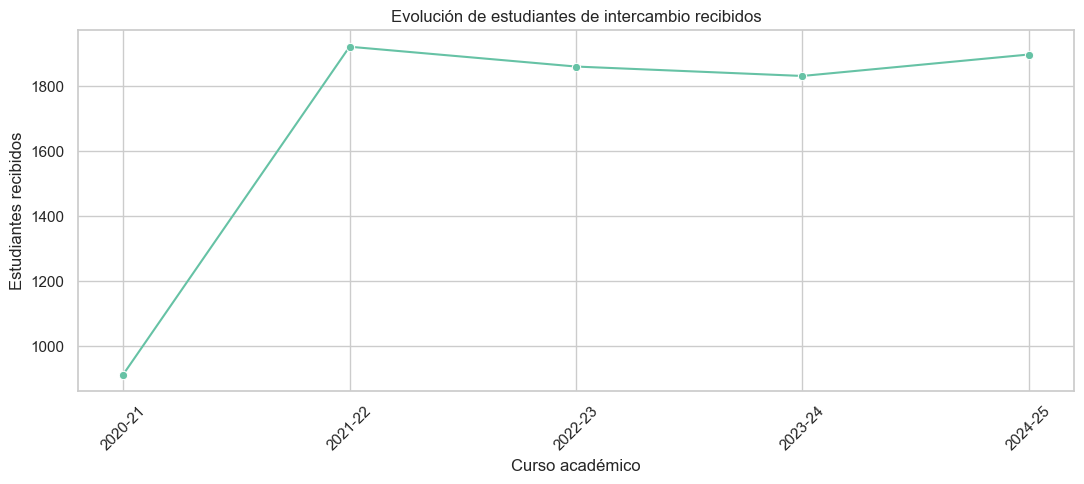

,CURSO,MOVILIDAD_ENTRANTE
0,2020-21,913.0
1,2021-22,1922.0
2,2022-23,1861.0
3,2023-24,1832.0
4,2024-25,1898.0


In [21]:

movilidad_anual = (
    df_movilidad.groupby("CURSO")["MOVILIDAD_ENTRANTE"]
    .sum(min_count=1)
    .reset_index()
)

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=movilidad_anual,
    x="CURSO",
    y="MOVILIDAD_ENTRANTE",
    marker="o"
)

plt.title("Evolución de estudiantes de intercambio recibidos")
plt.xlabel("Curso académico")
plt.ylabel("Estudiantes recibidos")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(movilidad_anual)


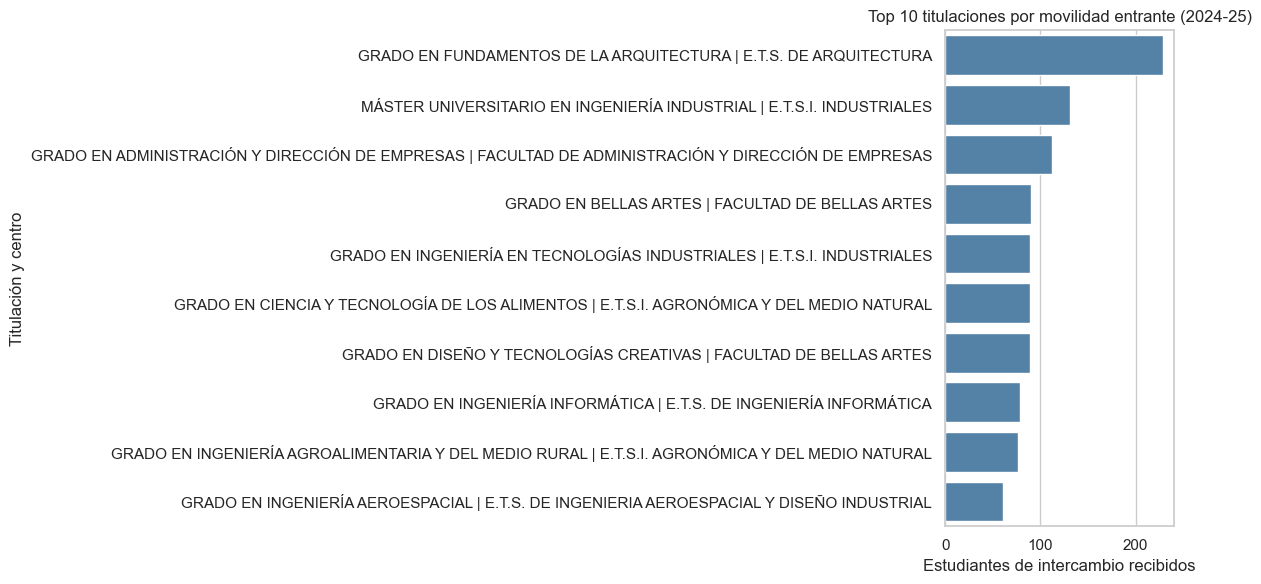

In [22]:

curso_seleccionado = "2024-25"

top_entrada = (
    df_movilidad[
        df_movilidad["CURSO"] == curso_seleccionado
    ]
    .dropna(subset=["MOVILIDAD_ENTRANTE"])
    .sort_values("MOVILIDAD_ENTRANTE", ascending=False)
    .head(10)
    .copy()
)

top_entrada["TITULACION_CENTRO"] = (
    top_entrada["TITULACION"] + " | "
    + top_entrada["CENTRO"]
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_entrada,
    x="MOVILIDAD_ENTRANTE",
    y="TITULACION_CENTRO",
    color="steelblue"
)

plt.title(f"Top 10 titulaciones por movilidad entrante ({curso_seleccionado})")
plt.xlabel("Estudiantes de intercambio recibidos")
plt.ylabel("Titulación y centro")
plt.tight_layout()
plt.show()


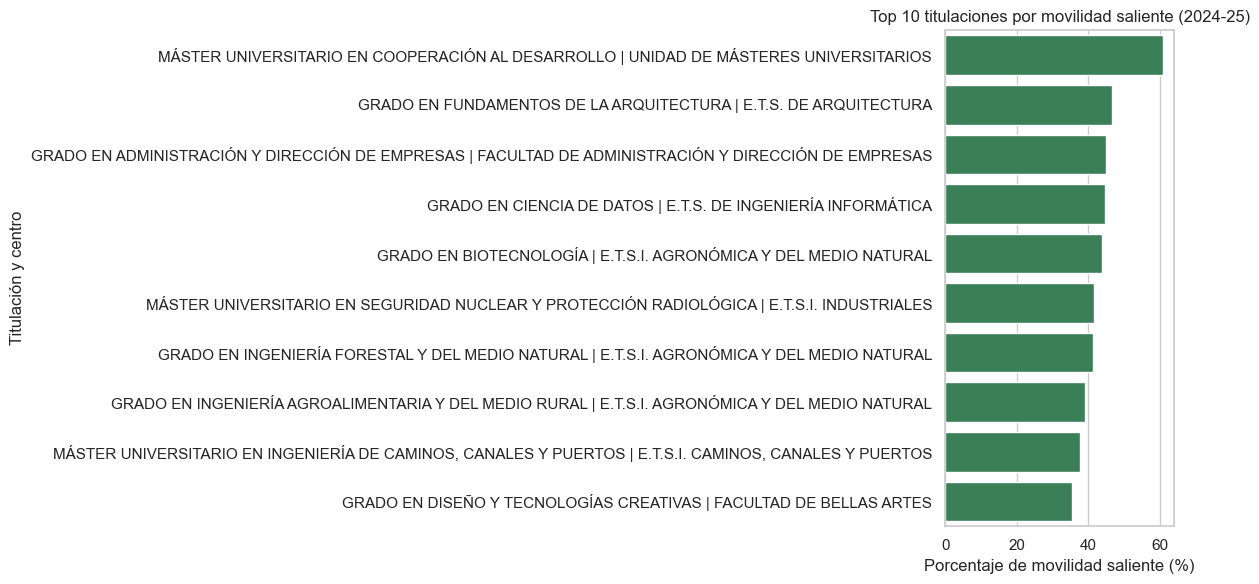

In [23]:

top_salida = (
    df_movilidad[
        df_movilidad["CURSO"] == curso_seleccionado
    ]
    .dropna(subset=["PORC_MOVILIDAD_SALIENTE"])
    .sort_values("PORC_MOVILIDAD_SALIENTE", ascending=False)
    .head(10)
    .copy()
)

top_salida["TITULACION_CENTRO"] = (
    top_salida["TITULACION"] + " | "
    + top_salida["CENTRO"]
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_salida,
    x="PORC_MOVILIDAD_SALIENTE",
    y="TITULACION_CENTRO",
    color="seagreen"
)

plt.title(f"Top 10 titulaciones por movilidad saliente ({curso_seleccionado})")
plt.xlabel("Porcentaje de movilidad saliente (%)")
plt.ylabel("Titulación y centro")
plt.tight_layout()
plt.show()


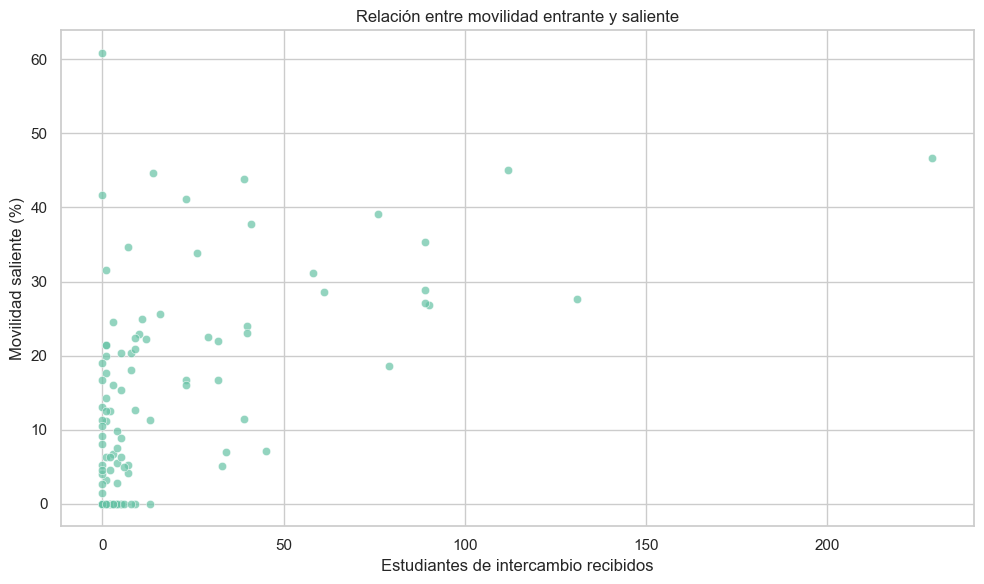

,MOVILIDAD_ENTRANTE,PORC_MOVILIDAD_SALIENTE
MOVILIDAD_ENTRANTE,1.000000,0.598894
PORC_MOVILIDAD_SALIENTE,0.598894,1.000000


In [24]:

df_relacion = df_movilidad[
    df_movilidad["CURSO"] == curso_seleccionado
].dropna(
    subset=["MOVILIDAD_ENTRANTE", "PORC_MOVILIDAD_SALIENTE"]
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_relacion,
    x="MOVILIDAD_ENTRANTE",
    y="PORC_MOVILIDAD_SALIENTE",
    alpha=0.7
)

plt.title("Relación entre movilidad entrante y saliente")
plt.xlabel("Estudiantes de intercambio recibidos")
plt.ylabel("Movilidad saliente (%)")
plt.tight_layout()
plt.show()

correlacion = df_relacion[
    ["MOVILIDAD_ENTRANTE", "PORC_MOVILIDAD_SALIENTE"]
].corr(method="spearman")

display(correlacion)


In [26]:

path_matricula = Path("../datos/Alumnos_matriculados_2020_2024.csv")

df_matricula = pd.read_csv(
    path_matricula,
    sep=";",
    encoding="utf-8-sig",
    dtype={"COD_RUCT": str}
)

display(df_matricula.head())
print(df_matricula.shape)


,CURSO,COD_RUCT,TITULACION,CENTRO,NUMERO_ALUMNOS_MATRICULADOS
0,2020-21,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,450
1,2020-21,2500801,GRADO EN CIENCIAS AMBIENTALES,ESCUELA POLITECNICA SUPERIOR DE GANDIA,224
2,2020-21,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,376
3,2020-21,2501355,GRADO EN TURISMO,ESCUELA POLITECNICA SUPERIOR DE GANDIA,378
4,2020-21,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E. POLITÉCNICA SUPERIOR DE ALCOY,356


(615, 5)


In [27]:

df_matricula["CENTRO"] = (
    df_matricula["CENTRO"].astype("string").str.strip()
)

df_matricula["CURSO"] = (
    df_matricula["CURSO"].astype(str).str.strip()
)

df_matricula["COD_RUCT"] = (
    df_matricula["COD_RUCT"].astype("string").str.strip()
)

print("Claves duplicadas en matrícula:")
display(
    df_matricula[
        df_matricula.duplicated(claves, keep=False)
    ]
)

assert not df_matricula.duplicated(claves).any(), \
    "Revisa las claves duplicadas en matrícula."

df_final = df_movilidad.merge(
    df_matricula[
        claves + ["NUMERO_ALUMNOS_MATRICULADOS"]
    ],
    on=claves,
    how="left",
    validate="one_to_one"
)

print("Registros sin matrícula:")
print(df_final["NUMERO_ALUMNOS_MATRICULADOS"].isna().sum())

display(df_final.head())


Claves duplicadas en matrícula:


,CURSO,COD_RUCT,TITULACION,CENTRO,NUMERO_ALUMNOS_MATRICULADOS


Registros sin matrícula:
180


,COD_RUCT,TITULACION,CENTRO,CURSO,MOVILIDAD_ENTRANTE,PORC_MOVILIDAD_SALIENTE,NUMERO_ALUMNOS_MATRICULADOS
0,2500739,GRADO EN ARQUITECTURA TÉCNICA,E.T.S. DE INGENIERÍA DE EDIFICACIÓN,2020-21,10.0,2.08,450.0
1,2500801,GRADO EN CIENCIAS AMBIENTALES,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,6.0,11.11,224.0
2,2501354,GRADO EN COMUNICACIÓN AUDIOVISUAL,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,14.0,21.05,376.0
3,2501355,GRADO EN TURISMO,ESCUELA POLITECNICA SUPERIOR DE GANDIA,2020-21,17.0,16.33,378.0
4,2501356,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,E. POLITÉCNICA SUPERIOR DE ALCOY,2020-21,2.0,14.93,356.0


In [28]:

df_final["RATIO_MOVILIDAD_ENTRANTE"] = (
    df_final["MOVILIDAD_ENTRANTE"]
    / df_final["NUMERO_ALUMNOS_MATRICULADOS"]
    .replace(0, np.nan)
) * 100

display(
    df_final[
        [
            "TITULACION",
            "CURSO",
            "NUMERO_ALUMNOS_MATRICULADOS",
            "MOVILIDAD_ENTRANTE",
            "RATIO_MOVILIDAD_ENTRANTE"
        ]
    ].head(10)
)


,TITULACION,CURSO,NUMERO_ALUMNOS_MATRICULADOS,MOVILIDAD_ENTRANTE,RATIO_MOVILIDAD_ENTRANTE
0,GRADO EN ARQUITECTURA TÉCNICA,2020-21,450.0,10.0,2.222222
1,GRADO EN CIENCIAS AMBIENTALES,2020-21,224.0,6.0,2.678571
2,GRADO EN COMUNICACIÓN AUDIOVISUAL,2020-21,376.0,14.0,3.723404
3,GRADO EN TURISMO,2020-21,378.0,17.0,4.497354
4,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,2020-21,356.0,2.0,0.561798
5,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,2020-21,NaN,<NA>,<NA>
6,GRADO EN INGENIERÍA EN DISEÑO INDUSTRIAL Y DES...,2020-21,664.0,33.0,4.96988
7,GRADO EN BELLAS ARTES,2020-21,1572.0,28.0,1.78117
8,GRADO EN CONSERVACIÓN Y RESTAURACIÓN DE BIENES...,2020-21,401.0,0.0,0.0
9,GRADO EN GESTIÓN Y ADMINISTRACIÓN PÚBLICA,2020-21,340.0,2.0,0.588235


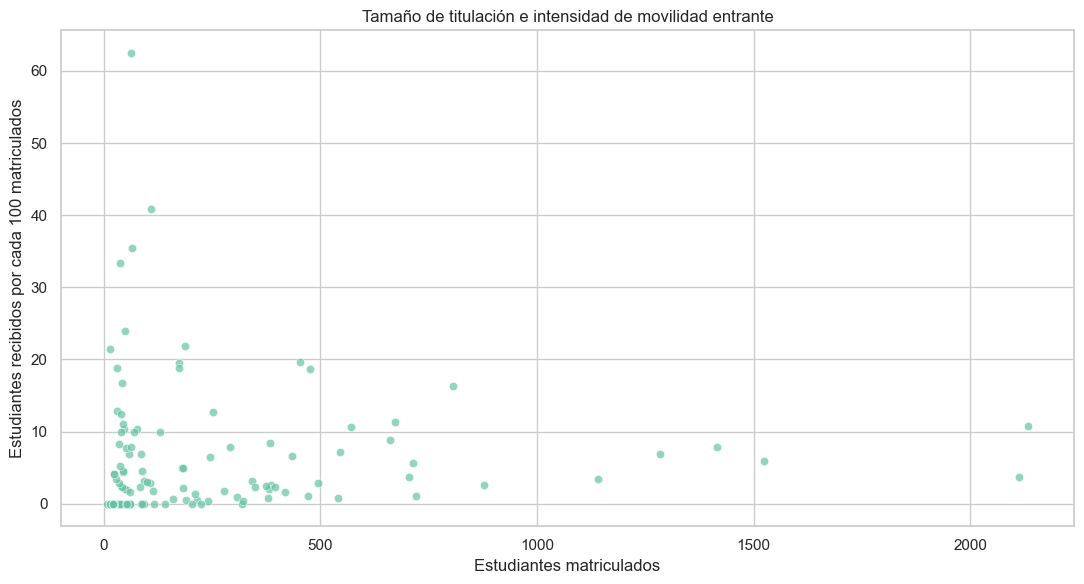

In [29]:

df_grafico = df_final[
    df_final["CURSO"] == curso_seleccionado
].dropna(
    subset=[
        "NUMERO_ALUMNOS_MATRICULADOS",
        "RATIO_MOVILIDAD_ENTRANTE"
    ]
)

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df_grafico,
    x="NUMERO_ALUMNOS_MATRICULADOS",
    y="RATIO_MOVILIDAD_ENTRANTE",
    alpha=0.7
)

plt.title("Tamaño de titulación e intensidad de movilidad entrante")
plt.xlabel("Estudiantes matriculados")
plt.ylabel("Estudiantes recibidos por cada 100 matriculados")
plt.tight_layout()
plt.show()


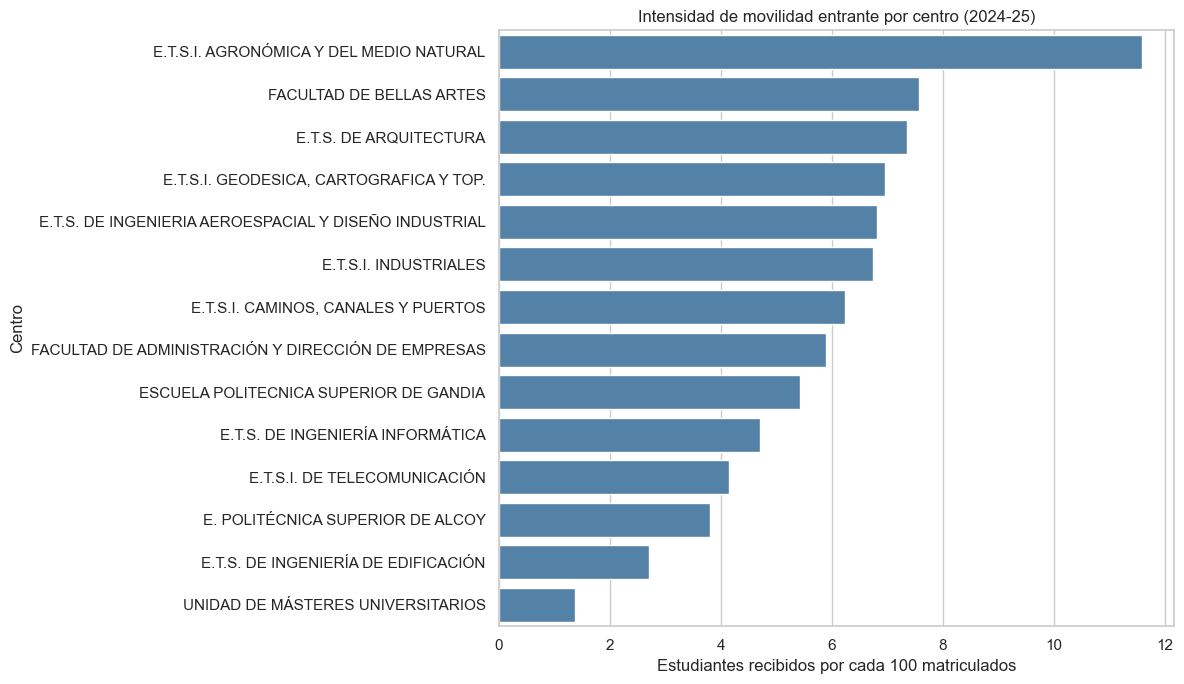

,CENTRO,estudiantes,movilidad_entrante,titulaciones,ratio_movilidad
5,E.T.S.I. AGRONÓMICA Y DEL MEDIO NATURAL,2347.0,272.0,10,11.589263
12,FACULTAD DE BELLAS ARTES,2547.0,193.0,4,7.577542
1,E.T.S. DE ARQUITECTURA,3536.0,260.0,5,7.352941
8,"E.T.S.I. GEODESICA, CARTOGRAFICA Y TOP.",374.0,26.0,2,6.951872
2,E.T.S. DE INGENIERIA AEROESPACIAL Y DISEÑO IND...,3620.0,247.0,12,6.823204
9,E.T.S.I. INDUSTRIALES,4133.0,279.0,14,6.750544
6,"E.T.S.I. CAMINOS, CANALES Y PUERTOS",1011.0,63.0,8,6.231454
11,FACULTAD DE ADMINISTRACIÓN Y DIRECCIÓN DE EMPR...,1918.0,113.0,6,5.891554
10,ESCUELA POLITECNICA SUPERIOR DE GANDIA,1289.0,70.0,12,5.430566
4,E.T.S. DE INGENIERÍA INFORMÁTICA,2968.0,140.0,6,4.716981


In [30]:

centros = (
    df_final[
        df_final["CURSO"] == curso_seleccionado
    ]
    .dropna(
        subset=[
            "MOVILIDAD_ENTRANTE",
            "NUMERO_ALUMNOS_MATRICULADOS"
        ]
    )
    .groupby("CENTRO", as_index=False)
    .agg(
        estudiantes=("NUMERO_ALUMNOS_MATRICULADOS", "sum"),
        movilidad_entrante=("MOVILIDAD_ENTRANTE", "sum"),
        titulaciones=("COD_RUCT", "nunique")
    )
)

centros["ratio_movilidad"] = (
    centros["movilidad_entrante"]
    / centros["estudiantes"].replace(0, np.nan)
    * 100
)

centros = centros.sort_values(
    "ratio_movilidad", ascending=False
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=centros,
    x="ratio_movilidad",
    y="CENTRO",
    color="steelblue"
)

plt.title(f"Intensidad de movilidad entrante por centro ({curso_seleccionado})")
plt.xlabel("Estudiantes recibidos por cada 100 matriculados")
plt.ylabel("Centro")
plt.tight_layout()
plt.show()

display(centros)


Estadísticos de investigación:


count       150.0
mean     7.783933
std      2.560766
min          2.45
25%           6.0
50%         7.665
75%         9.075
max         16.41
Name: CONTRIBUCIONES_TESIS, dtype: Float64


Valores ausentes:


COD_RUCT                 0
TITULACION               0
CURSO                    0
CONTRIBUCIONES_TESIS    10
dtype: int64

,CURSO,mean,median,count
0,2020-21,8.062333,8.18,30
1,2021-22,7.602069,7.33,29
2,2022-23,8.264667,8.625,30
3,2023-24,7.250968,7.43,31
4,2024-25,7.751333,7.345,30


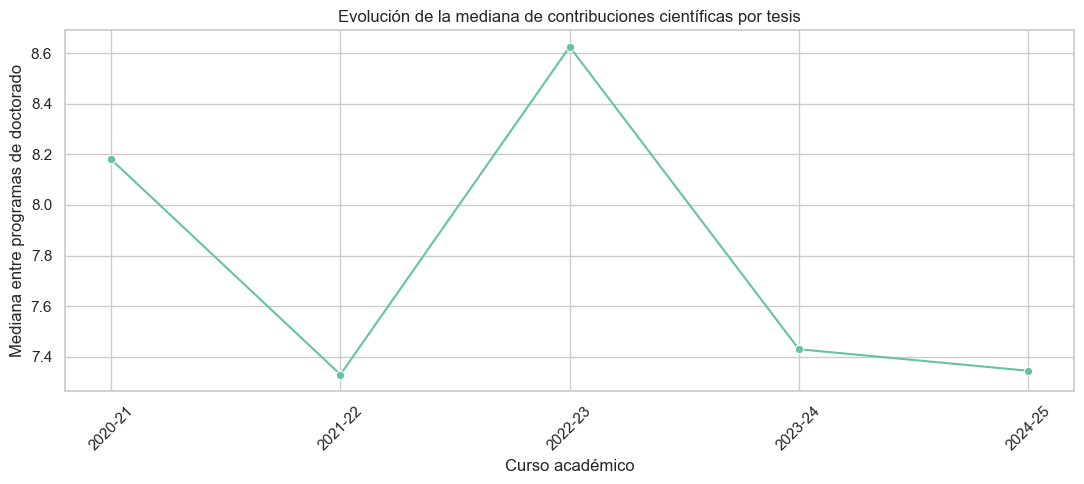

In [31]:

print("Estadísticos de investigación:")
display(investigacion["CONTRIBUCIONES_TESIS"].describe())

print("\nValores ausentes:")
display(investigacion.isna().sum())

# Evolución del promedio de contribuciones por programa
evolucion_investigacion = (
    investigacion.groupby("CURSO")["CONTRIBUCIONES_TESIS"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

display(evolucion_investigacion)

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=evolucion_investigacion,
    x="CURSO",
    y="median",
    marker="o"
)

plt.title("Evolución de la mediana de contribuciones científicas por tesis")
plt.xlabel("Curso académico")
plt.ylabel("Mediana entre programas de doctorado")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


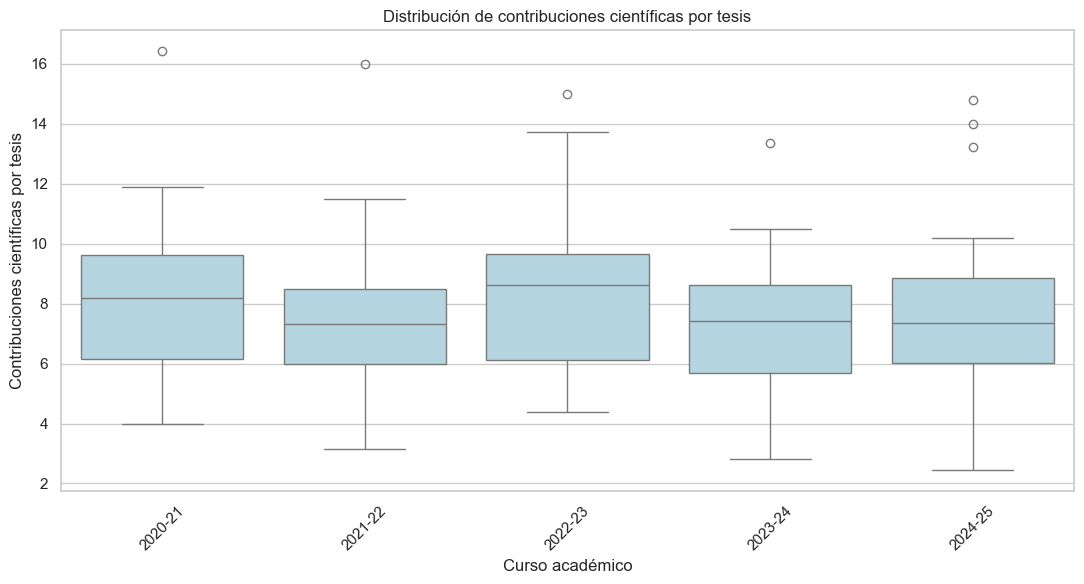

In [32]:

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=investigacion,
    x="CURSO",
    y="CONTRIBUCIONES_TESIS",
    color="lightblue"
)

plt.title("Distribución de contribuciones científicas por tesis")
plt.xlabel("Curso académico")
plt.ylabel("Contribuciones científicas por tesis")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

output_path = Path("data/processed")
output_path.mkdir(parents=True, exist_ok=True)

df_final.to_csv(
    output_path / "upv_titulaciones_eda.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset guardado correctamente.")
print("Dimensiones:", df_final.shape)

display(df_final.head())
